# 01 · Implied volatility, everywhere on the surface

Implied volatility is the common currency of this library: model and market prices are
compared through it, and the calibrators weight their losses by Black–Scholes vega.
Most implied-volatility code looks fine on at-the-money options and fails quietly
elsewhere. This notebook maps where each solver works on a grid from 1 day to 5 years
and from 0.3× to 3.3× the forward, explains the failures, and shows the fix.

Cells marked **PASS** are checks: they raise if the library stops behaving as described,
so running the notebook is also a test. Maths: [docs/black_scholes.md](../docs/black_scholes.md).

In [1]:
import time
import warnings

import _style as st
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm

from finpricing.models.black_scholes.implied_volatility import (
    ImpliedVolatilityCalculator,
    ImpliedVolatilityParams,
    Method,
)
from finpricing.utils.bs_utils import bs_price, bs_vega, implied_volatility

warnings.filterwarnings("ignore", category=RuntimeWarning)

## 1 · Prices and Greeks

`bs_price` and `bs_vega` are vectorised over every argument. The analytic Greeks below
are checked against central finite differences of `bs_price`, with a dividend yield so
the $e^{-qT}$ factors are exercised too.

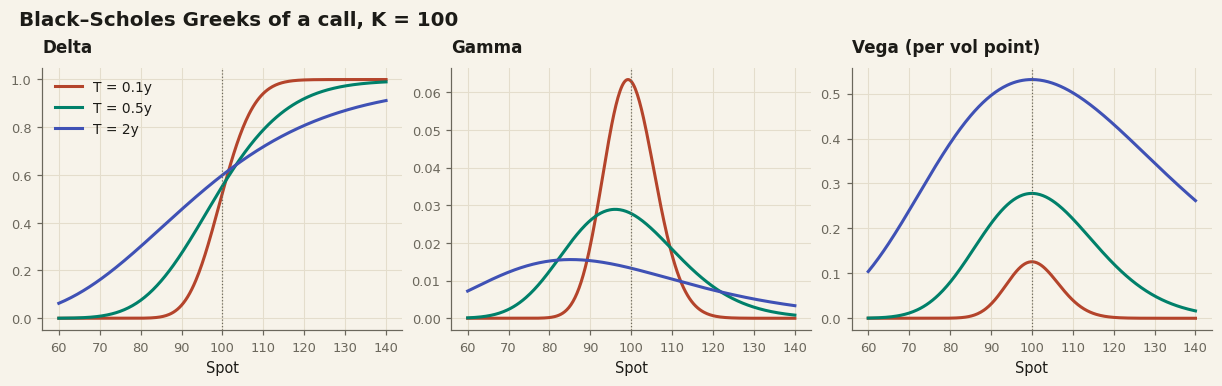

PASS  delta matches finite differences (max error 1.1e-07)
PASS  gamma matches finite differences (max error 1.3e-08)
PASS  bs_vega matches finite differences (max error 3.3e-08)


In [2]:
K, r, q, sigma = 100.0, 0.03, 0.01, 0.20
spots = np.linspace(60, 140, 321)
maturities = [0.1, 0.5, 2.0]


def d1(S, T):
    return (np.log(S / K) + (r - q + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))


def call(S, T, vol=sigma):
    return bs_price(S, K, T, r, vol, q)


delta_err = gamma_err = vega_err = 0.0
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for T, color in zip(maturities, st.SERIES, strict=False):
    delta = np.exp(-q * T) * norm.cdf(d1(spots, T))
    gamma = np.exp(-q * T) * norm.pdf(d1(spots, T)) / (spots * sigma * np.sqrt(T))
    vega = bs_vega(spots, K, T, r, sigma, q)

    h = 1e-4 * spots
    delta_err = max(delta_err, np.max(np.abs((call(spots + h, T) - call(spots - h, T)) / (2 * h) - delta)))
    gamma_err = max(gamma_err, np.max(np.abs(
        (call(spots + h, T) - 2 * call(spots, T) + call(spots - h, T)) / h**2 - gamma)))
    vega_err = max(vega_err, np.max(np.abs((call(spots, T, sigma + 1e-5) - call(spots, T, sigma - 1e-5)) / 2e-5 - vega)))

    for ax, y in zip(axes, [delta, gamma, vega / 100], strict=True):
        ax.plot(spots, y, color=color, label=f"T = {T:g}y")

for ax, title in zip(axes, ["Delta", "Gamma", "Vega (per vol point)"], strict=True):
    ax.set_title(title)
    ax.set_xlabel("Spot")
    ax.axvline(K, color=st.MUTED, lw=0.8, ls=":")
axes[0].legend(loc="upper left")
fig.suptitle("Black–Scholes Greeks of a call, K = 100", x=0.01, ha="left")
plt.show()

st.check(delta_err < 1e-6, f"delta matches finite differences (max error {delta_err:.1e})")
st.check(gamma_err < 1e-5, f"gamma matches finite differences (max error {gamma_err:.1e})")
st.check(vega_err < 1e-4, f"bs_vega matches finite differences (max error {vega_err:.1e})")

## 2 · What makes inversion possible, and where it gets hard

A call price is strictly increasing in volatility and lives between the no-arbitrage
bounds $\max(Se^{-qT} - Ke^{-rT}, 0)$ and $Se^{-qT}$, so every price inside the bounds
has exactly one implied volatility. The right panel shows why some solvers struggle:
vega, the slope they follow, is nearly flat at both ends for options away from the money.

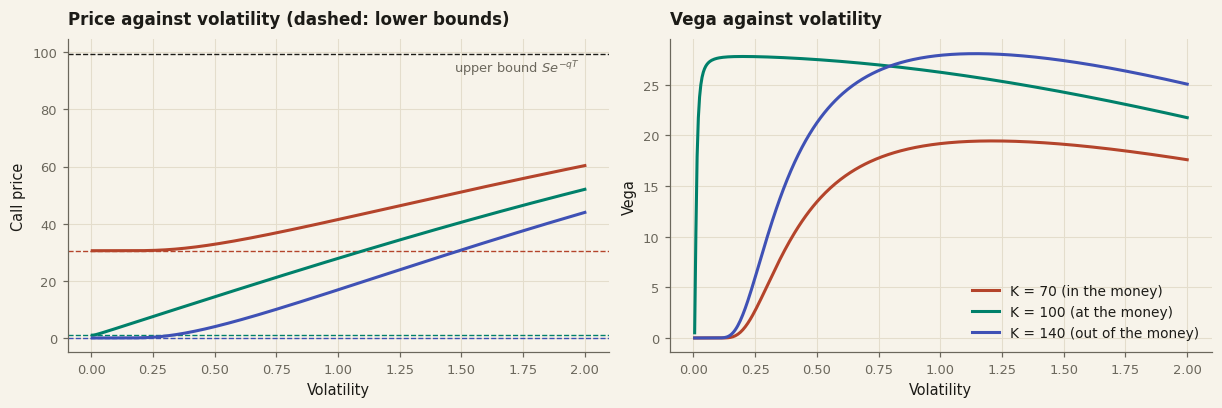

PASS  prices outside the no-arbitrage bounds give NaN, not an error
PASS  prices inside the bounds invert to the volatility that produced them
PASS  put–call parity holds


In [3]:
S0, T = 100.0, 0.5
vols = np.linspace(0.005, 2.0, 400)
strikes = {"K = 70 (in the money)": 70.0, "K = 100 (at the money)": 100.0, "K = 140 (out of the money)": 140.0}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
for (label, k), color in zip(strikes.items(), st.SERIES, strict=False):
    ax1.plot(vols, bs_price(S0, k, T, r, vols, q), color=color, label=label)
    ax1.axhline(max(S0 * np.exp(-q * T) - k * np.exp(-r * T), 0), color=color, lw=0.9, ls="--")
    ax2.plot(vols, bs_vega(S0, k, T, r, vols, q), color=color, label=label)
ax1.axhline(S0 * np.exp(-q * T), color=st.INK, lw=0.9, ls="--")
ax1.annotate("upper bound $Se^{-qT}$", (1.98, S0 * np.exp(-q * T)), xytext=(0, -12),
             textcoords="offset points", ha="right", fontsize=8.5, color=st.MUTED)
ax1.set(title="Price against volatility (dashed: lower bounds)", xlabel="Volatility", ylabel="Call price")
ax2.set(title="Vega against volatility", xlabel="Volatility", ylabel="Vega")
ax2.legend(loc="lower right")
plt.show()

# Prices outside the bounds have no implied volatility: the vectorised solver returns NaN.
k = np.array([80.0, 100.0, 120.0])
fair = bs_price(S0, k, T, r, 0.25, q)
lower = np.maximum(S0 * np.exp(-q * T) - k * np.exp(-r * T), 0)
bad = implied_volatility(np.r_[lower - 0.01, np.full(3, S0)], S0, np.r_[k, k], T, r, q)
st.check(np.all(np.isnan(bad)), "prices outside the no-arbitrage bounds give NaN, not an error")
st.check(np.allclose(implied_volatility(fair, S0, k, T, r, q), 0.25, atol=1e-10),
         "prices inside the bounds invert to the volatility that produced them")
parity = bs_price(S0, k, T, r, 0.25, q) - bs_price(S0, k, T, r, 0.25, q, "put")
st.check(np.allclose(parity, S0 * np.exp(-q * T) - k * np.exp(-r * T), atol=1e-12), "put–call parity holds")

## 3 · Five solvers on a hard grid

`ImpliedVolatilityCalculator` offers five solvers for a single call (no dividends):
bisection (`ITERATIVE`), Brent, Newton with vega, and two `scipy.optimize.root` methods.
Each one gets the same 400 call prices, generated at a true volatility of 25% across
log-moneyness $\ln(K/F)$ from −1.2 to 1.2 and maturities from one day to five years.

Hatched cells are quotes with no information left: the price is below $10^{-12}$, and no
solver should be expected to recover a volatility from it.

In [4]:
S0, r, true_vol = 100.0, 0.02, 0.25
log_m = np.linspace(-1.2, 1.2, 25)
mats = np.geomspace(1 / 252, 5, 16)
LM, TT = np.meshgrid(log_m, mats)
KK = S0 * np.exp(r * TT + LM)                      # strikes at the given ln(K/F)
call_prices = bs_price(S0, KK, TT, r, true_vol)
informative = call_prices > 1e-12

methods = [Method.ITERATIVE, Method.BRENTQ, Method.NEWTON, Method.HYBR, Method.LM]
errors, timings = {}, {}
for method in methods:
    err = np.full(KK.shape, np.nan)
    start = time.perf_counter()
    for idx in np.ndindex(KK.shape):
        if not informative[idx]:
            continue
        params = ImpliedVolatilityParams(call_value=float(call_prices[idx]), s=S0, k=float(KK[idx]),
                                         t=float(TT[idx]), r=r, method=method)
        try:
            vol = ImpliedVolatilityCalculator.implied_volatility(params)
            err[idx] = abs(vol - true_vol) if vol is not None and np.isfinite(vol) else 1.0
        except (ValueError, RuntimeError, ZeroDivisionError):
            err[idx] = 1.0                          # did not converge
    timings[method.name] = (time.perf_counter() - start) / informative.sum()
    errors[method.name] = err

# The vectorised solver in bs_utils, given the out-of-the-money option at each strike
otm = np.where(LM >= 0, "call", "put")
otm_prices = bs_price(S0, KK, TT, r, true_vol, option_type=otm)
otm_informative = otm_prices > 1e-12
start = time.perf_counter()
iv = implied_volatility(otm_prices, S0, KK, TT, r, option_type=otm)
timings["implied_volatility (OTM)"] = (time.perf_counter() - start) / KK.size
errors["implied_volatility (OTM)"] = np.where(otm_informative, np.abs(np.nan_to_num(iv, nan=1.0) - true_vol), np.nan)

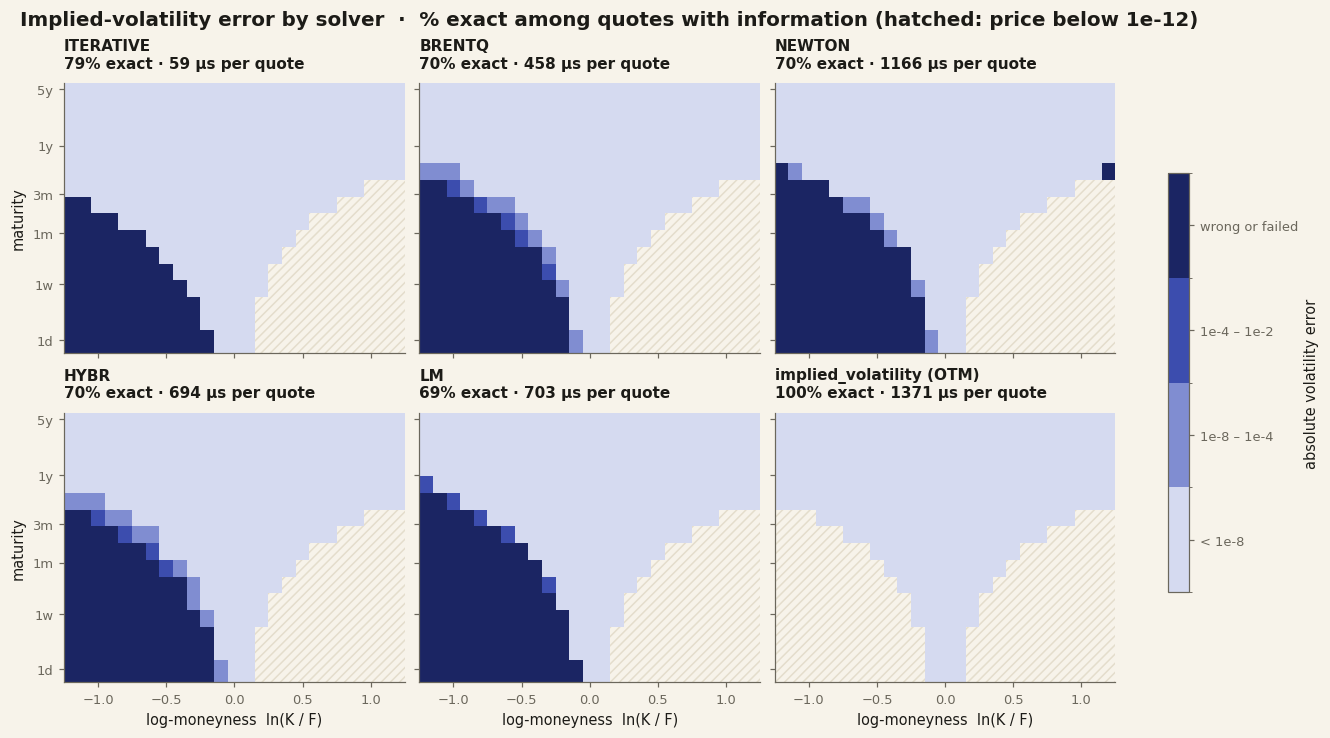

In [5]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Rectangle

bands = [0, 1e-8, 1e-4, 1e-2, 2]
band_labels = ["< 1e-8", "1e-8 – 1e-4", "1e-4 – 1e-2", "wrong or failed"]
cmap = ListedColormap(st.SEQUENTIAL(np.linspace(0.08, 1.0, 4)))
cmap.set_bad((0, 0, 0, 0))                          # no-information cells show the hatching
norm_bands = BoundaryNorm(bands, cmap.N)

fig, axes = plt.subplots(2, 3, figsize=(12, 6.6), sharex=True, sharey=True)
for ax, (name, err) in zip(axes.flat, errors.items(), strict=True):
    mesh = ax.pcolormesh(log_m, mats, np.ma.masked_invalid(err), cmap=cmap, norm=norm_bands, shading="nearest")
    ax.add_patch(Rectangle((0, 0), 1, 1, transform=ax.transAxes, hatch="////", fill=False,
                           edgecolor=st.GRID, lw=0, zorder=0))
    ok = np.mean(err[~np.isnan(err)] < 1e-8) * 100
    ax.set_title(f"{name}\n{ok:.0f}% exact · {timings[name] * 1e6:.0f} µs per quote", fontsize=10)
    ax.set_yscale("log")
    ax.set_yticks([1 / 252, 1 / 52, 1 / 12, 0.25, 1, 5], ["1d", "1w", "1m", "3m", "1y", "5y"])
    ax.minorticks_off()
    ax.grid(False)
for ax in axes[1]:
    ax.set_xlabel("log-moneyness  ln(K / F)")
for ax in axes[:, 0]:
    ax.set_ylabel("maturity")
cbar = fig.colorbar(mesh, ax=axes, ticks=[(a + b) / 2 for a, b in zip(bands[:-1], bands[1:], strict=True)],
                    shrink=0.7, label="absolute volatility error")
cbar.ax.set_yticklabels(band_labels)
fig.suptitle("Implied-volatility error by solver  ·  % exact among quotes with information (hatched: price below 1e-12)", x=0.01, ha="left")
st.save(fig, "implied_vol_solvers")
plt.show()

Two regions break the call-only solvers:

- **Deep in the money (left of centre).** A deep in-the-money call is
  its intrinsic value plus a tiny time value. In double precision the time value is lost
  in rounding, so the price carries almost no information about volatility.
- **Deep out of the money and short-dated.** The price is so small that the vega is
  effectively zero; Newton-type steps blow up, and bracketing methods stop at whatever
  volatility the tolerance allows.

The fix is to invert the **out-of-the-money option** at every strike: a put below the
forward, a call above it. By put–call parity it carries the same time value without
the intrinsic part. That is what the calibrators do, and the last panel shows it
recovers the volatility on every quote that has information.

In [6]:
call_exact = {name: np.nanmean(errors[name][informative] < 1e-8) for name in [m.name for m in methods]}
best = max(call_exact, key=call_exact.get)
st.check(max(call_exact.values()) < 0.9,
         f"every call-only solver fails somewhere (best: {best}, {call_exact[best]:.0%} exact)")
otm_err = errors["implied_volatility (OTM)"][otm_informative]
st.check(np.max(otm_err) < 1e-6,
         f"OTM inversion recovers all {otm_informative.sum()} informative quotes (max error {np.max(otm_err):.1e})")

PASS  every call-only solver fails somewhere (best: ITERATIVE, 79% exact)
PASS  OTM inversion recovers all 230 informative quotes (max error 2.5e-13)


In [7]:
st.summary()

8/8 checks passed
  PASS  delta matches finite differences (max error 1.1e-07)
  PASS  gamma matches finite differences (max error 1.3e-08)
  PASS  bs_vega matches finite differences (max error 3.3e-08)
  PASS  prices outside the no-arbitrage bounds give NaN, not an error
  PASS  prices inside the bounds invert to the volatility that produced them
  PASS  put–call parity holds
  PASS  every call-only solver fails somewhere (best: ITERATIVE, 79% exact)
  PASS  OTM inversion recovers all 230 informative quotes (max error 2.5e-13)
